In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [36]:
! pwd

/Users/tedscott/Library/CloudStorage/GoogleDrive-fishdaddyo@gmail.com/My Drive/PhD Work/Data/CMIP6/NEX-GDDP-CMIP6/FGOALS-g3/raw


In [35]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
os.mkdir('../../FGOALS-g3')
os.mkdir('../../FGOALS-g3/raw')
os.mkdir('../../FGOALS-g3/regridded')
os.chdir('../../FGOALS-g3/raw/')
! ls -al

total 0
drwxr-xr-x  2 tedscott  staff   64 Oct 13 08:03 .
drwxr-xr-x@ 4 tedscott  staff  128 Oct 13 08:03 ..


## Download files

In [37]:
process_yrs = np.arange(1961,2015,1)
#process_yrs = [1963]
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014])

In [ ]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "historical"#"ssp245"
realization = "r3i1p1f1"#"r4i1p1f1"
model = "FGOALS-g3"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


Time for 1961 :9.106467633333333 min


## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [31]:
scenario = "historical"#"ssp245"
realization = "r1i1p1f1"#"r4i1p1f1"
model = "BCC-CSM2-MR"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"
process_yrs = np.arange(1961,2015,1)

In [30]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex()

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 1961 :11.776368016666668 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 1962 :291.7835136333333 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


...

cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2012 :11.589562166666667 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2013 :11.582412616666666 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2014 :11.5852151 min
CPU times: user 9h 54min 37s, sys: 35min 8s, total: 10h 29min 45s
Wall time: 15h 17min 20s


In [32]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2014-01-01T12:00:00 ... 2014-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 20:11:31 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           fc3bfa0d-1d32-4d5a-ab38-13cd593668f5
    history:               Tue Oct 13 01:32:01 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

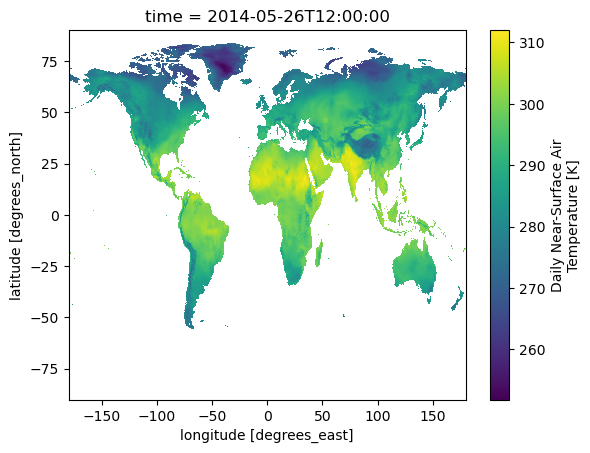

In [33]:
ds_model.tas.sel(time="2014-05-26").plot()